# Topic Modeling on the 20 Newsgroups Dataset

This notebook demonstrates **topic modeling** using the popular **20 Newsgroups text dataset**.  
Topic modeling is an **unsupervised machine learning technique** used to discover hidden thematic
structures (topics) in a large collection of documents.

In this notebook, we will:
- Load and explore the 20 Newsgroups dataset
- Preprocess raw text data
- Convert text into numerical representations using vectorization
- Apply topic modeling techniques
- Interpret and analyze the discovered topics

The goal is not only to build models, but also to **understand how different preprocessing and
vectorization choices affect topic quality and interpretability**.


In [ ]:
# Import core libraries: NumPy for numerical operations, sklearn for dataset and models,
# scipy for linear algebra, matplotlib for visualization
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from scipy import linalg
import matplotlib.pyplot as plt

In [ ]:
# Enable inline plotting in Jupyter/Colab and suppress scientific notation in NumPy
%matplotlib inline
np.set_printoptions(suppress=True)

## Data Loading and Exploration

In this section, we load the **20 Newsgroups dataset**, which consists of text documents
collected from different Usenet discussion groups. Each document belongs to a specific category,
making this dataset useful for both **supervised** and **unsupervised** learning tasks.

Although topic modeling does not use labels during training, exploring the dataset helps us:
- Understand the nature of the text data
- Inspect document length and vocabulary richness
- Get an intuition about the underlying themes present in the corpus

We will also restrict the dataset to a subset of categories to make topic interpretation clearer.


### Option 1: Loading the dataset through Scikit Learn

In [ ]:
# # Select 4 focused categories for clearer topic separation; remove noisy headers/footers/quotes
# categories = ['alt.atheism', 'talk.religion.misc', 'comp.graphics', 'sci.space']
# remove = ('headers', 'footers', 'quotes')
# # Load train/test splits with preprocessing applied
# newsgroups_train = fetch_20newsgroups(subset='train', categories=categories, remove=remove)
# newsgroups_test = fetch_20newsgroups(subset='test', categories=categories, remove=remove)

### Option 2: Downloading the Data locally and then loading it

In [ ]:
# from sklearn.datasets import fetch_20newsgroups
# from pathlib import Path

# data_home = Path("/content/")  # any path you want

import pickle
import codecs
from pathlib import Path

pkz_path = Path("/content/20news-bydate_py3.pkz")

with open(pkz_path, "rb") as f:
    compressed_content = f.read()

# Decode with zlib codec, then unpickle
uncompressed_content = codecs.decode(compressed_content, "zlib_codec")
cache = pickle.loads(uncompressed_content)


# `cache` is a dict with keys like 'train' and 'test'
train = cache["train"]
test = cache["test"]


categories = ['alt.atheism', 'talk.religion.misc', 'comp.graphics', 'sci.space']
remove = ('headers', 'footers', 'quotes')

newsgroups_train = fetch_20newsgroups(
    subset='train',
    categories=categories,
    remove=remove,
    # data_home=data_home,
    download_if_missing=True,
)

newsgroups_test = fetch_20newsgroups(
    subset='test',
    categories=categories,
    remove=remove,
    # data_home=data_home,
    download_if_missing=True,
)


# These objects are similar to what fetch_20newsgroups returns
train_data = train.data
train_target = train.target
train_target_names = train.target_names

test_data = test.data
test_target = test.target

np.array(newsgroups_train.data).shape, np.array(newsgroups_train.target).shape, np.array(newsgroups_test.data).shape, np.array(newsgroups_test.target).shape


((2034,), (2034,), (1353,), (1353,))

In [ ]:
# Verify dataset dimensions: (n_documents, ) for filenames and targets
newsgroups_train.filenames.shape, newsgroups_train.target.shape

((2034,), (2034,))

In [ ]:
print("\n".join(newsgroups_train.data[:3]))

Hi,

I've noticed that if you only save a model (with all your mapping planes
positioned carefully) to a .3DS file that when you reload it after restarting
3DS, they are given a default position and orientation.  But if you save
to a .PRJ file their positions/orientation are preserved.  Does anyone
know why this information is not stored in the .3DS file?  Nothing is
explicitly said in the manual about saving texture rules in the .PRJ file. 
I'd like to be able to read the texture rule information, does anyone have 
the format for the .PRJ file?

Is the .CEL file format available from somewhere?

Rych


Seems to be, barring evidence to the contrary, that Koresh was simply
another deranged fanatic who thought it neccessary to take a whole bunch of
folks with him, children and all, to satisfy his delusional mania. Jim
Jones, circa 1993.


Nope - fruitcakes like Koresh have been demonstrating such evil corruption
for centuries.

 >In article <1993Apr19.020359.26996@sq.sq.com>, msb@sq.sq.c

In [ ]:
# Map numeric targets to category names for first 3 documents
np.array(newsgroups_train.target_names)[newsgroups_train.target[:3]]

array(['comp.graphics', 'talk.religion.misc', 'sci.space'], dtype='<U18')

In [ ]:
newsgroups_train.target[:10]

array([1, 3, 2, 0, 2, 0, 2, 1, 2, 1])

In [ ]:
num_topics, num_top_words = 6, 8

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sorted(list(ENGLISH_STOP_WORDS))[:20]

['a',
 'about',
 'above',
 'across',
 'after',
 'afterwards',
 'again',
 'against',
 'all',
 'almost',
 'alone',
 'along',
 'already',
 'also',
 'although',
 'always',
 'am',
 'among',
 'amongst',
 'amoungst']

In [ ]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
from nltk import stem

In [ ]:
wnl = stem.WordNetLemmatizer()
porter = stem.porter.PorterStemmer()

In [ ]:
word_list = ['feet', 'foot', 'foots', 'footing']

In [ ]:
[wnl.lemmatize(word) for word in word_list]

['foot', 'foot', 'foot', 'footing']

In [ ]:
[porter.stem(word) for word in word_list]

['feet', 'foot', 'foot', 'foot']

## Text Preprocessing

Raw text data contains a lot of noise such as punctuation, stopwords, and formatting artifacts.
Before applying topic modeling algorithms, the text must be cleaned and normalized.

Effective preprocessing helps:
- Reduce vocabulary size
- Remove irrelevant or overly frequent terms
- Improve topic coherence and stability

Common preprocessing steps include:
- Lowercasing text
- Removing stopwords
- Ignoring extremely rare and extremely frequent words
- Tokenization and vectorization

In this notebook, preprocessing is handled implicitly during the vectorization step using
Scikit-learn's built-in tools.


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

## Text Vectorization

Machine learning models cannot operate directly on raw text.  
Therefore, documents must be transformed into **numerical feature vectors**.

We use vectorization techniques to represent text as:
- **Bag of Words (CountVectorizer)**: Counts how often each word appears
- **TF-IDF (TfidfVectorizer)**: Scales word counts by how informative they are across documents

Key parameters used here:
- `max_df`: Removes words that appear in too many documents (likely uninformative)
- `min_df`: Removes words that appear in very few documents (likely noise)
- `stop_words='english'`: Removes common English stopwords

These parameters significantly influence topic quality and interpretability.


In [ ]:
vectorizer = CountVectorizer(stop_words='english',max_df=0.9, min_df=0.05) #, tokenizer=LemmaTokenizer())

In [ ]:
vectors = vectorizer.fit_transform(newsgroups_train.data).todense() # (documents, vocab)
vectors.shape #, vectors.nnz / vectors.shape[0], row_means.shape

(2034, 107)

In [ ]:
print(len(newsgroups_train.data), vectors.shape)

2034 (2034, 107)


In [ ]:
vocab = np.array(vectorizer.get_feature_names_out())
vocab[:20]

array(['actually', 'agree', 'available', 'based', 'believe', 'better',
       'bible', 'bit', 'book', 'called', 'case', 'come', 'course', 'data',
       'day', 'did', 'didn', 'different', 'does', 'doesn'], dtype=object)

In [ ]:
vocab.shape

(107,)

In [ ]:
vocab[7000:7020]

array([], dtype=object)

In [ ]:
%time U, s, Vh = linalg.svd(vectors, full_matrices=False)

CPU times: user 44.1 ms, sys: 2.03 ms, total: 46.1 ms
Wall time: 46.2 ms


In [ ]:
print(U.shape, s.shape, Vh.shape)

(2034, 107) (107,) (107, 107)


In [ ]:
s[:4]

array([267.47695199, 167.17268883, 158.82178207, 136.97295262])

In [ ]:
np.diag(np.diag(s[:4]))

array([267.47695199, 167.17268883, 158.82178207, 136.97295262])

In [ ]:
num_top_words=8

def show_topics(a):
    top_words = lambda t: [vocab[i] for i in np.argsort(t)[:-num_top_words-1:-1]]
    topic_words = ([top_words(t) for t in a])
    return [' '.join(t) for t in topic_words]

In [ ]:
show_topics(Vh[:10])

['yes idea agree maybe thanks didn trying reason',
 'space nasa god year earth people time new',
 'space edu graphics nasa mail data available program',
 'graphics edu god mail people believe religion bible',
 'data god available nasa information believe religion bible',
 'data people like time said available make just',
 'nasa available don bit information better want use',
 'example true used bible nasa does question given',
 'edu people nasa said image day course come',
 'bible said does bit know say use far']

In [ ]:
m,n=vectors.shape
d=5  # num topics

## Topic Modeling

Topic modeling is an **unsupervised learning approach** that identifies latent themes
within a collection of documents. Each topic is represented as a distribution over words,
and each document is represented as a mixture of topics.

In this notebook, topic modeling helps us:
- Discover hidden thematic structures
- Group documents by semantic similarity
- Interpret dominant themes without labeled data

Different topic modeling algorithms make different assumptions about how documents
and topics are generated, which impacts the results.



## *Topic Modeling with Non-Negative Matrix Factorization (NMF)*

Non-Negative Matrix Factorization (NMF) is a matrix decomposition technique well-suited
for topic modeling when combined with TF-IDF features.

NMF works by factorizing the document-term matrix into:
- A document-topic matrix
- A topic-word matrix

Because all values are non-negative, the resulting topics are often more interpretable.
Each topic can be understood by examining the highest-weighted words associated with it.



In [ ]:
from sklearn import decomposition

In [ ]:
vectors = np.asarray(vectors)   # convert np.matrix → np.ndarray

clf = decomposition.NMF(n_components=d, random_state=1)
W1 = clf.fit_transform(vectors)
H1 = clf.components_

In [ ]:
show_topics(H1)

['image use bit available data program don does',
 'space nasa year earth program new time information',
 'god people does believe just religion don bible',
 'edu graphics mail help based line support like',
 'data available nasa information edu program set based']

In [ ]:
# Create TF-IDF vectorizer: transforms text to sparse term-frequency inverse-document-frequency matrix
vectorizer_tfidf = TfidfVectorizer(stop_words='english',max_df=0.9, min_df=0.05)
# Fit vectorizer on training data and transform to get TF-IDF feature matrix (n_docs x n_features)
vectors_tfidf = vectorizer_tfidf.fit_transform(newsgroups_train.data) # (documents, vocab)

In [ ]:
newsgroups_train.data[10:20]

["a\n\nWhat about positional uncertainties in S-L 1993e?   I assume we know where\nand what Galileo is doing within a few meters.   But without the\nHGA,  don't we have to have some pretty good ideas, of where to look\nbefore imaging?  If the HGA was working,  they could slew around\nin near real time (Less speed of light delay).  But when they were\nimaging toutatis????  didn't someone have to get lucky on a guess to\nfind the first images?   \n\nAlso, I imagine S-L 1993e will be mostly a visual image.  so how will\nthat affect the other imaging missions.  with the LGA,  there is a real\ntight allocation of bandwidth.   It may be premature to hope for answers,\nbut I thought i'd throw it on the floor.",
 "I would like to program Tseng ET4000 to nonstandard 1024x768 mode by\nswitching to standard 1024x768 mode using BIOS and than changing some\ntiming details (0x3D4 registers 0x00-0x1F) but I don't know how to\nselect 36 MHz pixel clock I need. The BIOS function selects 40 MHz.\n\nIs t

In [ ]:
# Fit NMF model: extracts document-topic weights (W1) and topic-word weights (H1)
W1 = clf.fit_transform(vectors_tfidf)
H1 = clf.components_

## Topic Interpretation

Each topic is represented by a set of high-weight words. The meaning of a topic
is inferred by analyzing these words collectively rather than individually.


In [ ]:
# Display top 8 words per topic using learned vocabulary for interpretation
show_topics(H1)

['don just people think like time say good',
 'space nasa earth data program year years available',
 'thanks graphics image edu program need mail information',
 'god believe bible say edu true people life',
 'does know like say didn looking far sure']

### Topic Interpretation and Analysis

Each topic below is interpreted by examining the group of high-probability words
associated with it. The meaning of a topic is inferred from the collective context
of these words rather than from individual terms.

---

#### Topic 1 – General Conversation and Opinions

**Top words:**  
don, just, people, think, like, time, say, good

**Interpretation:**  
This topic represents general conversational language and opinion-based discussion.
The words *people*, *think*, *say*, and *time* indicate informal discourse where
individuals express thoughts, perspectives, or everyday reasoning rather than
discussing a specific technical or factual subject.

---

#### Topic 2 – Space Science and NASA Programs

**Top words:**  
space, nasa, earth, data, program, year, years, available

**Interpretation:**  
This topic is clearly centered around space science and NASA-related programs.
The presence of words such as *space*, *nasa*, and *earth* suggests discussions
related to space exploration, scientific data, and long-term research programs.
Terms like *data* and *available* indicate an informational or research-oriented
context.

---

#### Topic 3 – Computer Graphics and Academic Information Exchange

**Top words:**  
thanks, graphics, image, edu, program, need, mail, information

**Interpretation:**  
This topic focuses on computer graphics and information exchange in an academic
setting. Words such as *graphics*, *image*, and *program* suggest technical
discussions, while *edu*, *mail*, and *information* imply communication or
requests commonly found in academic or educational environments.

---

#### Topic 4 – Religion, Belief, and Life Philosophy

**Top words:**  
god, believe, bible, say, edu, true, people, life

**Interpretation:**  
This topic reflects discussions around religion and belief systems. The grouping
of *god*, *bible*, and *believe* indicates religious discourse, while words like
*true*, *life*, and *people* suggest philosophical reflections and debates about
faith, truth, and human values.

---

#### Topic 5 – Uncertainty, Questions, and Informal Inquiry

**Top words:**  
does, know, like, say, didn, looking, far, sure

**Interpretation:**  
This topic captures informal questioning and expressions of uncertainty. Words
such as *does*, *know*, *looking*, and *sure* indicate exploratory or inquisitive
discussion, where users are seeking clarification, expressing doubt, or thinking
through a problem without a definitive conclusion.

---

#### Summary

The five topics capture a mix of:
- Informal conversational discourse
- Scientific and technical discussions
- Academic and information-sharing communication
- Religious and philosophical debate
- Inquiry-driven and uncertain reasoning

Together, these topics reflect the diverse nature of discussions present in the
dataset.


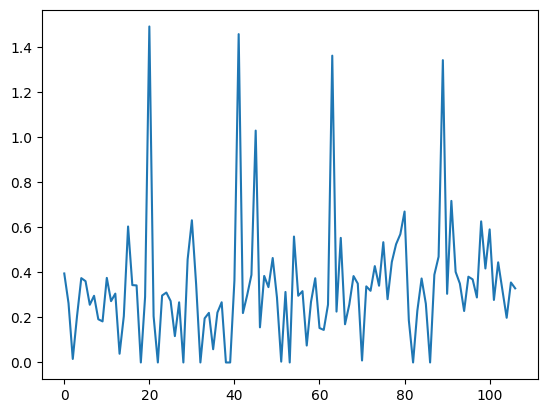

In [ ]:
# Visualize word importance distribution for Topic 0 (first component)
plt.plot(clf.components_[0])

In [ ]:
clf.reconstruction_err_

np.float64(39.288511479377426)